# Zmap TOWN II 建物割当検証：全日付・全地域

`Processed_Stay_Zmap_TOWN_II.py` の `prepare_activity()`、`extract_inside_region()`、`load_buildings()`、`assign_building()` をそのまま利用します。入力Parquetを10万行単位で読み、全期間・両地域の件数を集計します。元Notebookの建物品質検査、距離帯別Top20、距離ヒストグラム、地図を維持します。

**注意**：地図のGPS滞在点は各距離帯で最大20,000点の先頭サンプルです。件数・順位は全件から計算します。`MAX_NEAREST_DISTANCE_M`（既存コード側の探索上限）は変更しません。

## 1. 設定と既存モジュール

In [1]:
from pathlib import Path
from collections import Counter
import importlib.util
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.offsetbox import AnchoredText
from IPython.display import display
import contextily as ctx
from adjustText import adjust_text

ROOT = Path.home() / "gps_colocation_analysis"
SCRIPT_PATH = ROOT / "02_Scripts/Processed/Processed_Stay_Zmap_TOWN_II.py"
BATCH_SIZE = 100_000
DISTANCE_EDGES = [0, 50, 100, 150, 200, 300, 400, 500]
HIST_BIN_WIDTH = 10
TOP_N = 20
MAX_MAP_POINTS = 20_000       # 各地域・距離帯ごとの描画上限（集計には無関係）
MAKE_MAPS = True              # Falseにすると2周目の読み込みと地図を省略
MAP_CRS = "EPSG:3857"
GSI_URL = "https://cyberjapandata.gsi.go.jp/xyz/seamlessphoto/{z}/{x}/{y}.jpg"
GSI_ZOOM = 14
plt.rcParams["font.family"] = "Noto Sans CJK JP"
plt.rcParams["axes.unicode_minus"] = False

if not SCRIPT_PATH.is_file():
    raise FileNotFoundError(SCRIPT_PATH)
spec = importlib.util.spec_from_file_location("existing_building_process", SCRIPT_PATH)
original = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = original
spec.loader.exec_module(original)       # main()は呼ばない
REGION_LABELS = list(original.REGIONS)  # 既存スクリプトに登録されている全地域
PARQUET_FILES = sorted(original.INPUT_DIR.glob("trips_*.parquet"))
if not PARQUET_FILES:
    raise FileNotFoundError(f"Parquetがありません: {original.INPUT_DIR}")
print("地域:", REGION_LABELS)
print("入力ファイル数:", len(PARQUET_FILES))
print("最近傍探索上限(m):", original.MAX_NEAREST_DISTANCE_M)

地域: ['西条_5km', '広島_5km']
入力ファイル数: 489
最近傍探索上限(m): 500.0


## 2. 建物品質の確認（地域別・既存条件）

In [2]:
def summarize_raw_buildings(buildings: gpd.GeoDataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """建物GPKGの未加工データの品質を集計する。

    引数: buildings はGPKGから直接読み込んだ建物GeoDataFrame。
    戻り値: 品質項目別件数、geometry種類別件数。
    処理条件: 欠損と空geometryを別集計し、名称はstrip後に判定する。
    """
    if "housename" not in buildings.columns:
        raise KeyError("housename列がありません")
    geom = buildings.geometry
    names = buildings["housename"].astype("string").str.strip()
    n_names = names.str.count("/") + 1 # polygonに含まれる建物名の数
    valid_polygons = geom.notna() & ~geom.is_empty & buildings.geom_type.isin(["Polygon", "MultiPolygon"])
    items = {
        "全建物": len(buildings),
        "geometry欠損": int(geom.isna().sum()),
        "geometry空": int((geom.notna() & geom.is_empty).sum()),
        "Polygon": int(buildings.geom_type.eq("Polygon").sum()),
        "MultiPolygon": int(buildings.geom_type.eq("MultiPolygon").sum()),
        "その他geometry（欠損・空を除く）": int((geom.notna() & ~geom.is_empty & ~buildings.geom_type.isin(["Polygon", "MultiPolygon"])).sum()),
        "Polygon/MultiPolygonの無効geometry": int((valid_polygons & ~geom.is_valid).sum()),
        "housename欠損": int(names.isna().sum()),
        "housename空白（strip後）": int(names.eq("").sum()),
        "housename単一（/なし）": int((names.ne("") & n_names.eq(1)).sum()),
        "housename複数（/あり）": int((names.ne("") & n_names.gt(1)).sum()),
    }
    return (pd.DataFrame({"項目": items.keys(), "件数": items.values()}),
            buildings.geom_type.fillna("欠損").value_counts(dropna=False).rename_axis("geometry種類").reset_index(name="件数"))
#fillna()：Nanデータを"欠損"の文字に置き換える

REGION_DATA = {}
for label in REGION_LABELS:
    config = original.REGIONS[label]
    raw = gpd.read_file(config["shp"])
    quality, types = summarize_raw_buildings(raw)
    names = raw["housename"].astype("string").str.strip()
    duplicates = names[names.notna() & names.ne("")].value_counts()
    duplicates = duplicates[duplicates > 1].rename_axis("housename").reset_index(name="ポリゴン件数")
    buildings, geometry = original.load_buildings(config["shp"], config["buffer"], label)
    REGION_DATA[label] = (buildings, geometry)
    print(f"\n===== {label} =====")
    print(f"入力建物={len(raw):,} → 使用建物={len(buildings):,} / 同名建物名={len(duplicates):,}種類")
    display(quality, types, duplicates)
    display(buildings["n_names"].value_counts(dropna=False).rename_axis("名称数").reset_index(name="建物数"))
    del raw

[西条_5km] 無効なgeometryを0件削除
[西条_5km] 建物 23,242件 / 無効geometry除外 0件 / CRS EPSG:30163

===== 西条_5km =====
入力建物=40,839 → 使用建物=23,242 / 同名建物名=1,664種類


,項目,件数
0,全建物,40839
1,geometry欠損,0
2,geometry空,0
3,Polygon,40839
4,MultiPolygon,0
5,その他geometry（欠損・空を除く）,0
6,Polygon/MultiPolygonの無効geometry,0
7,housename欠損,17597
8,housename空白（strip後）,0
9,housename単一（/なし）,23242


,geometry種類,件数
0,Polygon,40839


,housename,ポリゴン件数
0,山本,96
1,田中,74
2,佐々木,70
3,伊藤,58
4,山田,56
...,...,...
1659,綿本,2
1660,芋岡,2
1661,羽田野,2
1662,栗川駐輪場,2


,名称数,建物数
0,1,23242


[広島_5km] 無効なgeometryを0件削除
[広島_5km] 建物 134,963件 / 無効geometry除外 0件 / CRS EPSG:30163

===== 広島_5km =====
入力建物=182,179 → 使用建物=134,963 / 同名建物名=25,783種類


,項目,件数
0,全建物,182179
1,geometry欠損,0
2,geometry空,0
3,Polygon,182179
4,MultiPolygon,0
5,その他geometry（欠損・空を除く）,0
6,Polygon/MultiPolygonの無効geometry,0
7,housename欠損,47216
8,housename空白（strip後）,0
9,housename単一（/なし）,134963


,geometry種類,件数
0,Polygon,182179


,housename,ポリゴン件数
0,田中,442
1,山本,427
2,中村,394
3,佐々木,354
4,松本,267
...,...,...
25778,z合,2
25779,見明,2
25780,平繁,2
25781,（有）つかさ設備,2


,名称数,建物数
0,1,134963


## 3. 全ファイルを100,000行ずつ読み込み、全期間の集計を作成

- 各バッチで、既存の滞在抽出・地域抽出・建物割当を実行します。
- 距離帯は元のNotebookと同じく **0–50mは両端を含む、以降は下端を含まず上端を含む** 判定です。
- 日付別の結果は保存せず、全期間の件数と建物別件数だけ蓄積します。
- 元の空間結合が1滞在につき複数行を返した場合は、その出力行数を維持して数えます。

In [3]:
COLUMNS = ["User_Id", "Trip_Id", "TripMode", "Latitude_start",
           "Longitude_start", "Latitude_end", "Longitude_end"]


def iter_region_results(files, region_data, batch_size):
    """全日別Parquetを分割して、各地域の建物割当結果を順に返す。

    引数: filesは日別ファイル一覧、region_dataは地域別の建物と範囲、batch_sizeは読込行数。
    戻り値: (ファイル名, 地域名, 入力滞在件数, 割当結果)を逐次返す。
    処理条件: 滞在・範囲・建物付与の判定は既存関数に委ねる。
    """
    for i, path in enumerate(files, 1):
        print(f"[{i}/{len(files)}] {path.name}", end="\r")
        parquet = pq.ParquetFile(path)
        missing = set(COLUMNS) - set(parquet.schema_arrow.names)
        if missing:
            raise KeyError(f"{path.name}: 列が不足しています: {sorted(missing)}")
        for batch in parquet.iter_batches(batch_size=batch_size, columns=COLUMNS):
            activity = original.prepare_activity(batch.to_pandas())
            for label, (buildings, geometry) in region_data.items():
                inside = original.extract_inside_region(activity, buildings.crs, geometry)
                if not inside.empty:
                    yield path.name, label, len(inside), original.assign_building(inside, buildings)
    print()


def distance_bands(distance):
    """最近傍距離を元Notebookと同じ右閉区間の距離帯へ分類する。

    引数: distanceは最近傍距離(m)のSeries。
    戻り値: 距離帯番号のSeries（対象外は欠損）。
    処理条件: [0,50], (50,100], ... , (400,500]を使用する。
    """
    return pd.cut(distance, bins=DISTANCE_EDGES, include_lowest=True, labels=False)


def aggregate_results(files, region_data, batch_size):
    """全期間の割当件数・距離分布・建物別距離帯件数を集計する。

    引数: filesは入力一覧、region_dataは地域データ、batch_sizeは分割読込行数。
    戻り値: 地域別集計辞書。
    処理条件: 建物割当成功はhousename非欠損、距離分布は最近傍割当成功のみ。
    """
    stats = {label: {"counts": Counter(), "hist": Counter(), "top": Counter(),
                     "distance_sum": 0.0, "distance_n": 0} for label in region_data}
    for _, label, n_input, result in iter_region_results(files, region_data, batch_size):
        st = stats[label]
        polygon = result["building_match_type"].eq("polygon_intersection")
        nearest = result["building_match_type"].eq("nearest_polygon")
        success = result["housename"].notna()
        st["counts"].update({"入力": n_input, "ポリゴン内一致": int(polygon.sum()),
            "ポリゴン外": int(nearest.sum()), "最近傍成功": int((nearest & success).sum()),
            "最近傍失敗": int((nearest & ~success).sum()), "出力": len(result)})
        part = result.loc[nearest & success & result["nearest_distance_m"].notna(),
                          ["housename", "nearest_distance_m"]].copy()
        if part.empty:
            continue
        distances = part["nearest_distance_m"]
        st["distance_sum"] += float(distances.sum())
        st["distance_n"] += len(distances)
        for v, count in (np.floor(distances / HIST_BIN_WIDTH) * HIST_BIN_WIDTH).value_counts().items():
            st["hist"][int(v)] += int(count)
        part["band"] = distance_bands(distances)
        for (band, name), count in part.dropna(subset=["band", "housename"]).groupby(["band", "housename"]).size().items():
            st["top"][(int(band), name)] += int(count)
    return stats


STATS = aggregate_results(PARQUET_FILES, REGION_DATA, BATCH_SIZE)

    ポリゴン内一致: 5 / 44801.parquet
    最近傍割当: 39
    建物割当成功: 44 / 44
    ポリゴン内一致: 89 / 290
    最近傍割当: 310
    建物割当成功: 438 / 438
    ポリゴン内一致: 7 / 32
    最近傍割当: 25
    建物割当成功: 32 / 32
    ポリゴン内一致: 63 / 231
    最近傍割当: 246
    建物割当成功: 342 / 342
    ポリゴン内一致: 5 / 29
    最近傍割当: 24
    建物割当成功: 29 / 29
    ポリゴン内一致: 64 / 256
    最近傍割当: 264
    建物割当成功: 355 / 355
    ポリゴン内一致: 11 / 36
    最近傍割当: 25
    建物割当成功: 36 / 36
    ポリゴン内一致: 57 / 219
    最近傍割当: 249
    建物割当成功: 340 / 340
    ポリゴン内一致: 6 / 35
    最近傍割当: 29
    建物割当成功: 35 / 35
    ポリゴン内一致: 75 / 291
    最近傍割当: 321
    建物割当成功: 440 / 440
    ポリゴン内一致: 8 / 42
    最近傍割当: 34
    建物割当成功: 42 / 42
    ポリゴン内一致: 77 / 282
    最近傍割当: 294
    建物割当成功: 402 / 402
    ポリゴン内一致: 8 / 36
    最近傍割当: 28
    建物割当成功: 36 / 36
    ポリゴン内一致: 103 / 342
    最近傍割当: 333
    建物割当成功: 488 / 488
    ポリゴン内一致: 6 / 42
    最近傍割当: 36
    建物割当成功: 42 / 42
    ポリゴン内一致: 124 / 373
    最近傍割当: 373
    建物割当成功: 545 / 545
    ポリゴン内一致: 4 / 14
    最近傍割当: 10
    建物割当成功: 14 / 14
    ポリゴン内一致: 95 / 298
    最近

## 4. 全期間の分類件数と最近傍距離分布


===== 西条_5km：全期間 =====


,分類,件数
0,入力,487552
1,ポリゴン内一致,91426
2,ポリゴン外,396390
3,最近傍成功,396017
4,最近傍失敗,373
5,出力,487816


注意：入力件数と割当出力行数が異なります（複数空間結合候補などを確認してください）


,距離下限(m),距離上限(m),件数
0,0,10,173663
1,10,20,94909
2,20,30,44821
3,30,40,22344
4,40,50,13366
5,50,60,8052
6,60,70,5665
7,70,80,4173
8,80,90,3298
9,90,100,3098


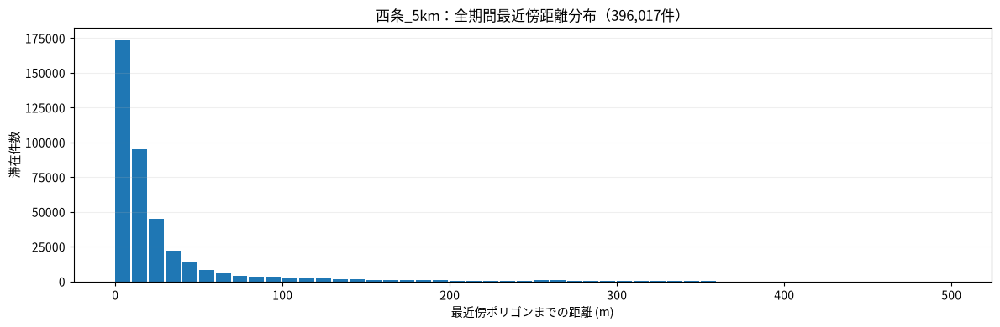

平均距離: 26.43 m

===== 広島_5km：全期間 =====


,分類,件数
0,入力,3075553
1,ポリゴン内一致,1360383
2,ポリゴン外,3124696
3,最近傍成功,3124638
4,最近傍失敗,58
5,出力,4485079


注意：入力件数と割当出力行数が異なります（複数空間結合候補などを確認してください）


,距離下限(m),距離上限(m),件数
0,0,10,1795213
1,10,20,686073
2,20,30,257040
3,30,40,136891
4,40,50,89226
5,50,60,48804
6,60,70,33238
7,70,80,20373
8,80,90,14612
9,90,100,10953


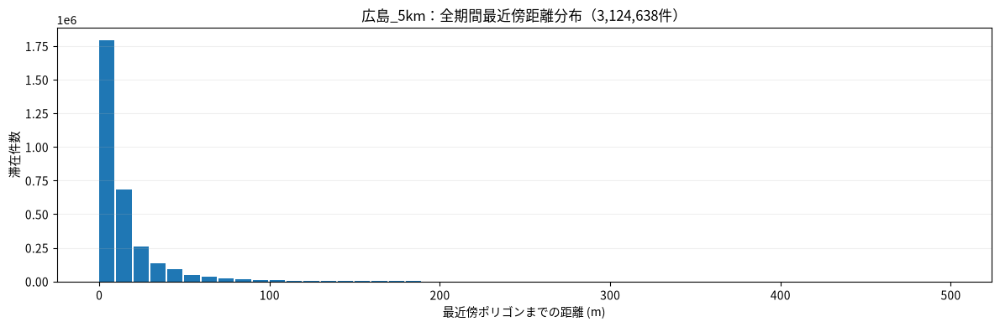

平均距離: 14.53 m


In [4]:
def show_summary(stats):
    """地域別の全期間件数・最近傍距離ヒストグラムを表示する。

    引数: statsはaggregate_results()の集計辞書。
    戻り値: なし（表とグラフを表示）。
    処理条件: 距離は既存の最近傍割当成功データのみを数える。
    """
    for label, st in stats.items():
        print(f"\n===== {label}：全期間 =====")
        display(pd.DataFrame(st["counts"].items(), columns=["分類", "件数"]))
        if st["counts"]["入力"] != st["counts"]["出力"]:
            print("注意：入力件数と割当出力行数が異なります（複数空間結合候補などを確認してください）")
        hist = pd.DataFrame(sorted(st["hist"].items()), columns=["距離下限(m)", "件数"])
        if hist.empty:
            print("最近傍割当成功地点がありません")
            continue
        hist["距離上限(m)"] = hist["距離下限(m)"] + HIST_BIN_WIDTH
        display(hist[["距離下限(m)", "距離上限(m)", "件数"]])
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.bar(hist["距離下限(m)"], hist["件数"], width=HIST_BIN_WIDTH * .9, align="edge")
        ax.set(xlabel="最近傍ポリゴンまでの距離 (m)", ylabel="滞在件数",
               title=f"{label}：全期間最近傍距離分布（{st['distance_n']:,}件）")
        ax.grid(axis="y", alpha=.2)
        plt.tight_layout()
        plt.show()
        print(f"平均距離: {st['distance_sum'] / st['distance_n']:.2f} m")


show_summary(STATS)

## 5. 全期間の距離帯別Top20（集計表・棒グラフ）


===== 西条_5km：0–50 m =====


,housename,滞在件数
0,シャープ（株）,4216
1,西条駅,3946
2,フジグラン東広島,2594
3,ハローズ東広島モール,2511
4,ＴＳＵＴＡＹＡ東広島店,1904
5,広島大学,1721
6,ゆめタウン東広島本館,1661
7,鮮Ｄｏ！エブリイ西条御薗宇店,1464
8,ＩＫＯＣＣＡエブリイ西条寺家店,1413
9,ゆめタウン学園店,1275


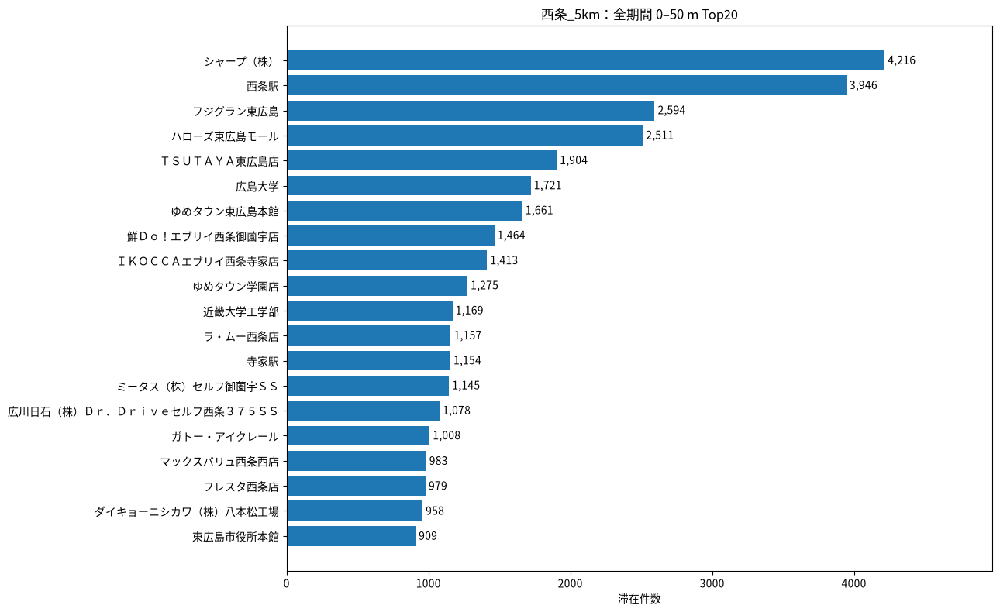


===== 西条_5km：50–100 m =====


,housename,滞在件数
0,ガトー・アイクレール,1678
1,広島大学,1475
2,（有）スカイオート,983
3,酒井史朗,963
4,東広島市消防局,944
5,近畿大学工学部,557
6,広島大学北第３福利会館,386
7,西地区エネルギーセンター,383
8,井上政秋,327
9,南部,287


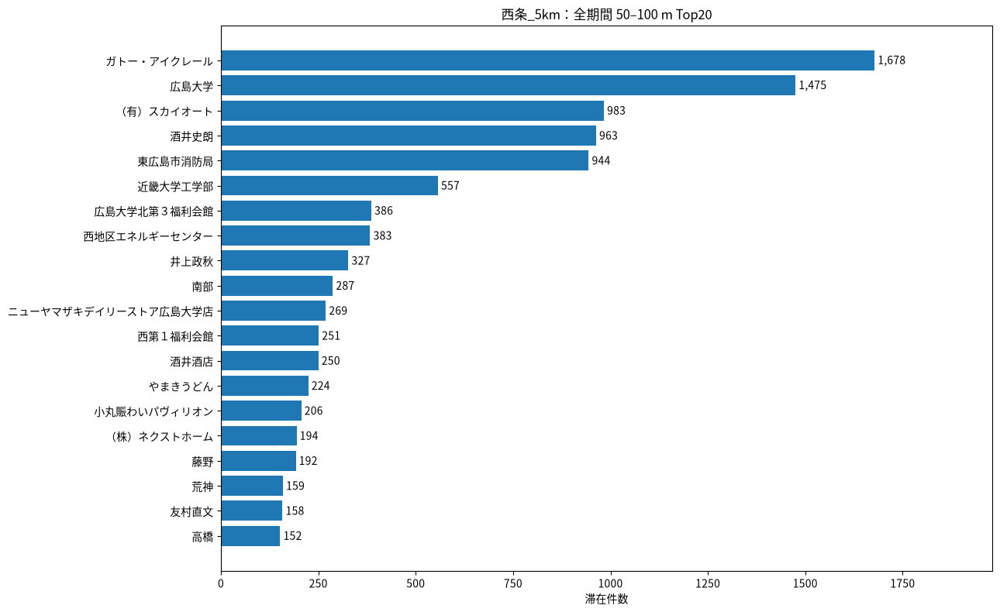


===== 西条_5km：100–150 m =====


,housename,滞在件数
0,広島大学,997
1,酒井史朗,744
2,（有）スカイオート,629
3,森川元康,410
4,友村直文,382
5,西地区エネルギーセンター,363
6,ガトー・アイクレール,335
7,西第１福利会館,328
8,友村博文,319
9,パスティーユ,319


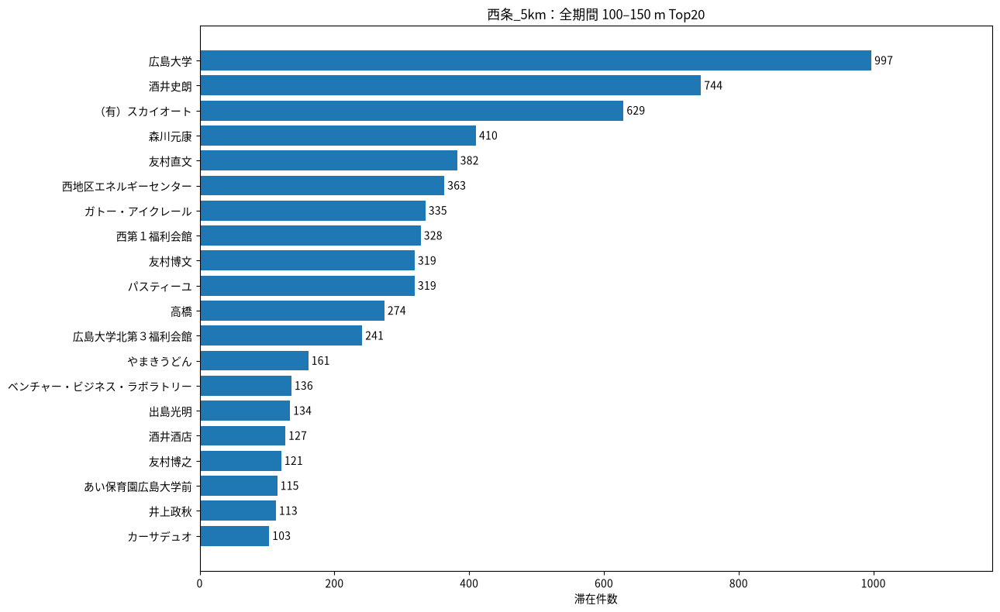


===== 西条_5km：150–200 m =====


,housename,滞在件数
0,広島大学,1125
1,高橋,518
2,やまきうどん,332
3,井上政秋,159
4,出島光明,138
5,森川元康,127
6,西地区エネルギーセンター,103
7,ガーデンパレスＡ,96
8,ベンチャー・ビジネス・ラボラトリー,88
9,（有）スカイオート,84


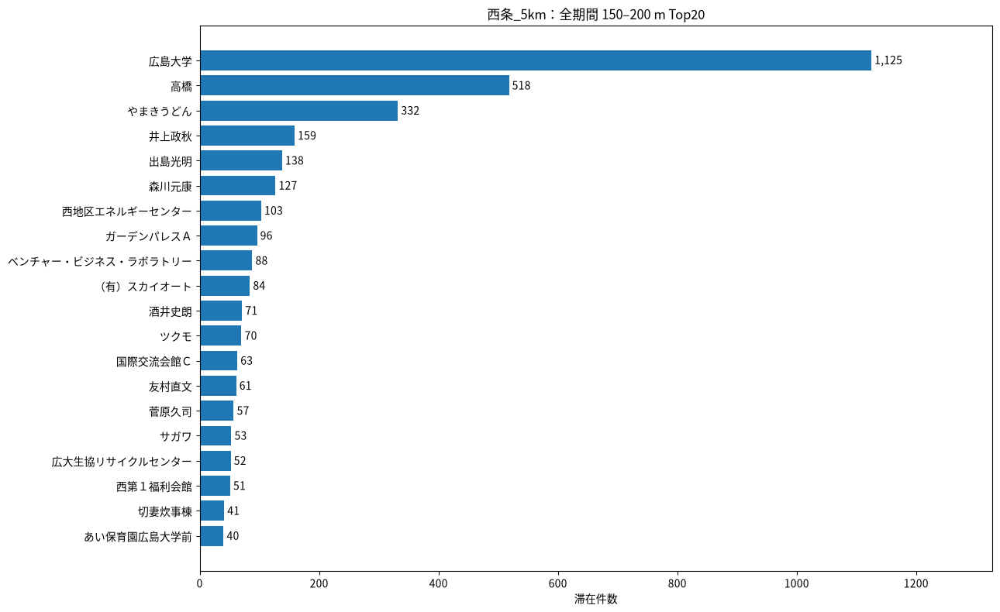


===== 西条_5km：200–300 m =====


,housename,滞在件数
0,高橋,2462
1,広島大学,735
2,やまきうどん,587
3,三歩,265
4,出島光明,184
5,国際交流会館Ｃ,135
6,ベンチャー・ビジネス・ラボラトリー,115
7,ガーデンパレスＡ,106
8,いすゞ自動車中国四国（株）西条サービスセンター,77
9,イシモト,64


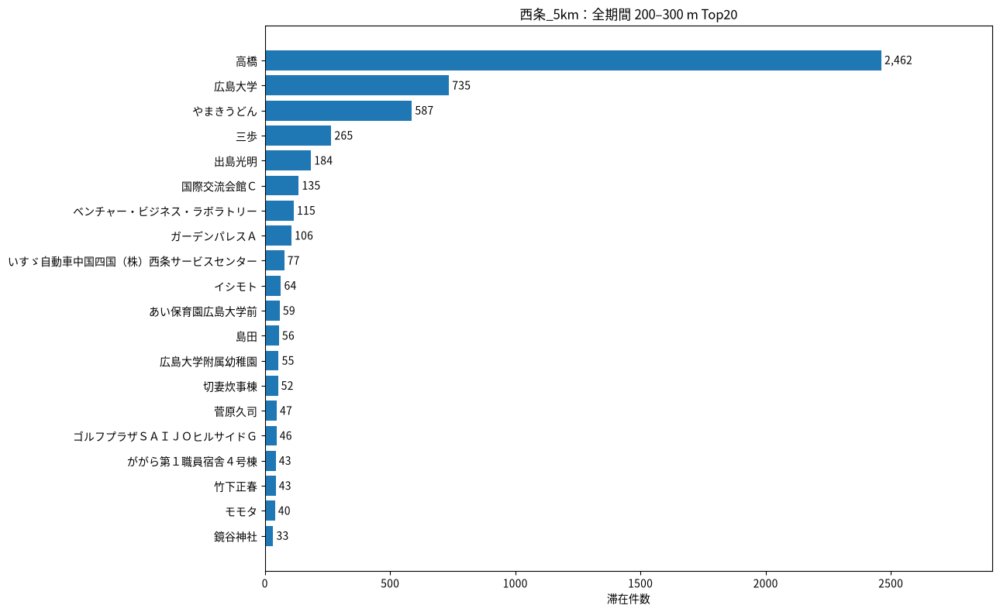


===== 西条_5km：300–400 m =====


,housename,滞在件数
0,広島中央環境衛生組合賀茂環境衛生センター,220
1,やまきうどん,135
2,広島中央環境衛生組合賀茂環境衛生センター多目的広場,126
3,高橋,82
4,切妻炊事棟,80
5,広島大学,51
6,広島大学附属幼稚園,50
7,（株）大創産業本社別館,47
8,寺山堂,28
9,金盛憲二,26


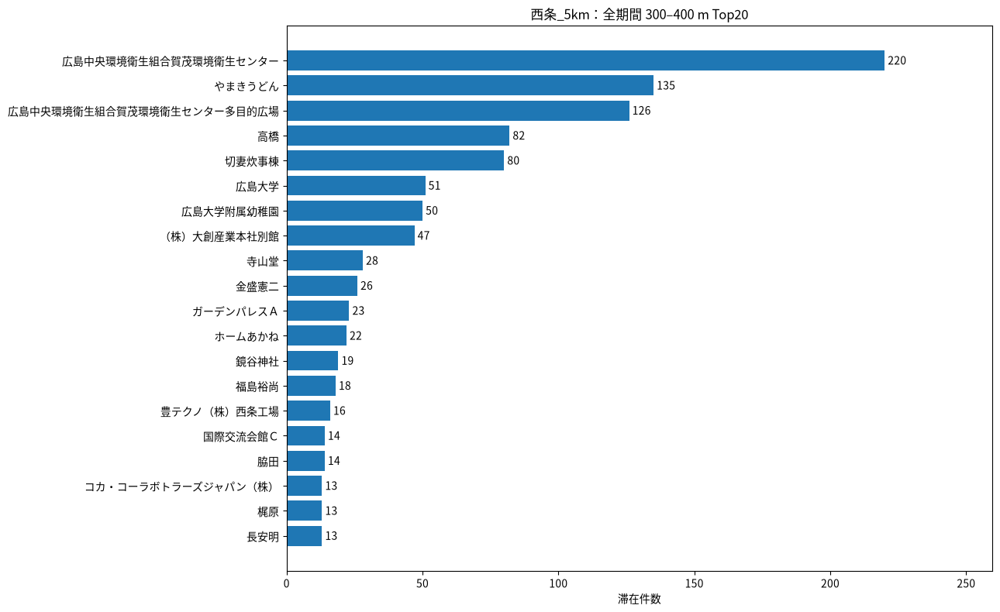


===== 西条_5km：400–500 m =====


,housename,滞在件数
0,切妻炊事棟,47
1,ホームあかね,27
2,まつやセロファン（株）,16
3,岡本賢司,14
4,杉西,12
5,中下,10
6,井上,9
7,広島中央環境衛生組合賀茂環境衛生センター,8
8,（株）大創産業本社別館,8
9,増本誠,8


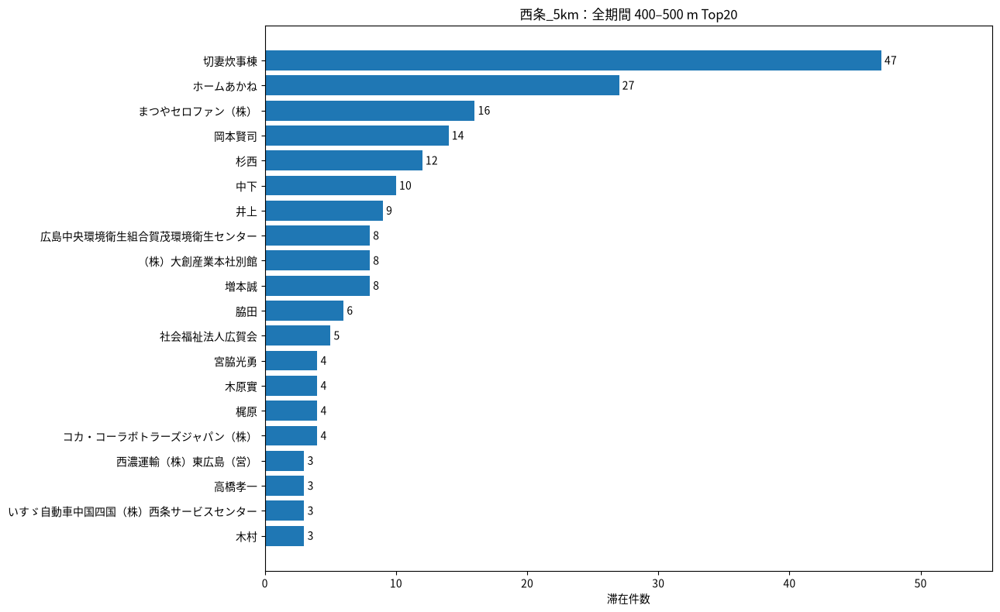


===== 広島_5km：0–50 m =====


,housename,滞在件数
0,広島駅,56830
1,福屋広島駅前店エールエールＡ館,21465
2,イオンモール広島府中,21440
3,ｅｋｉｅＤＩＮＩＮＧ・おみやげ館・エキエバル,19876
4,ひろしま駅ビルアッセ,19196
5,イズミ新本社ビル,12504
6,シェラトングランドホテル広島,9768
7,ＢＩＧＦＲＯＮＴひろしま西棟,9648
8,ゆめタウン広島,9520
9,西部高架下,9477


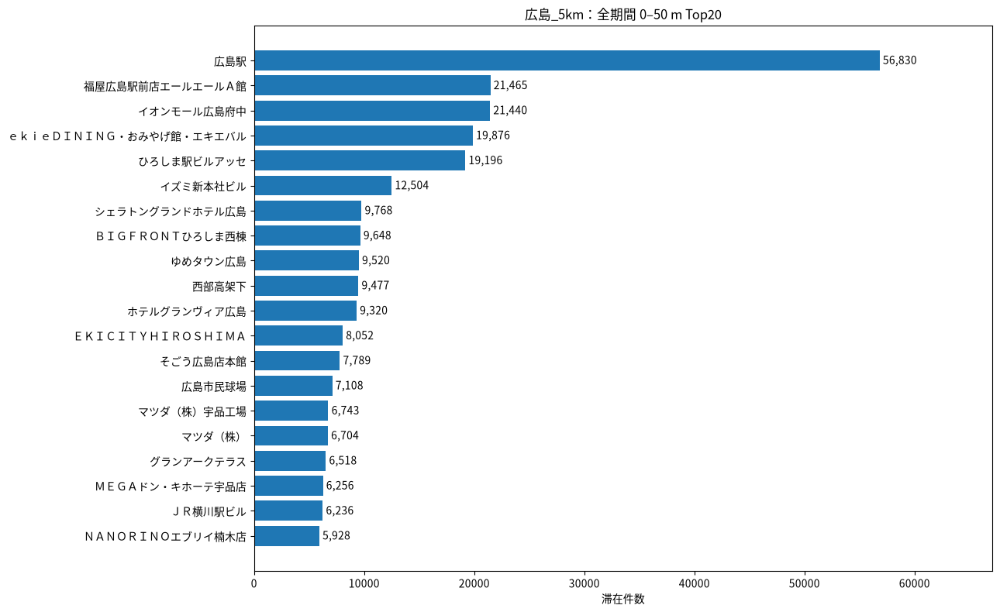


===== 広島_5km：50–100 m =====


,housename,滞在件数
0,広島駅,3018
1,マツダ（株）宇品工場,2474
2,マツダ（株）,2044
3,国立広島原爆死没者追悼平和祈念館,1939
4,広島市民球場,1713
5,西日本旅客鉄道（株）広島支社,1562
6,ｅｋｉｅＤＩＮＩＮＧ・おみやげ館・エキエバル,1284
7,広島護国神社,1259
8,グランアークテラス,1242
9,ｈｉｔｏｔｏ広島ナレッジスクエア,1086


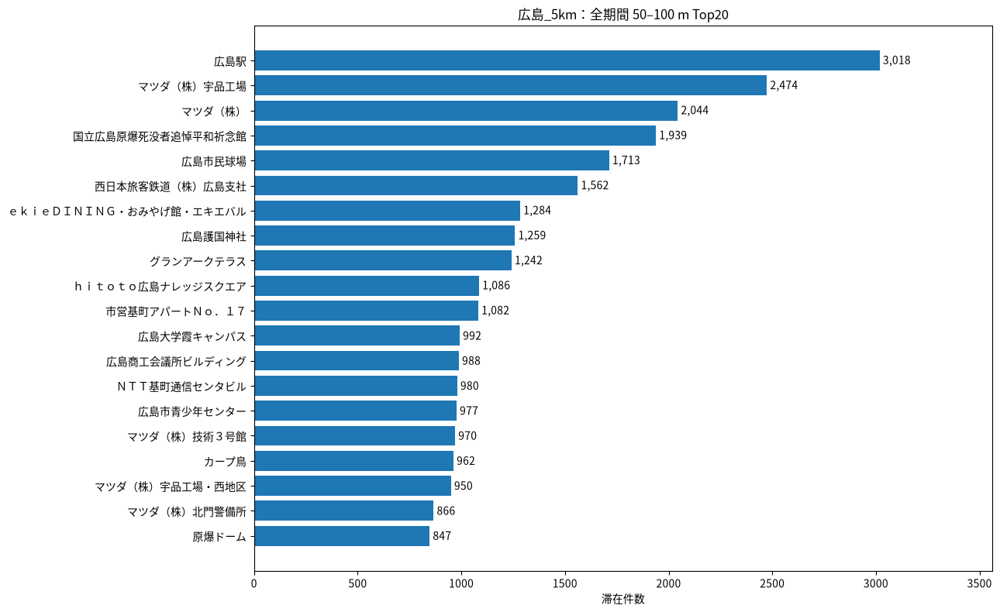


===== 広島_5km：100–150 m =====


,housename,滞在件数
0,市営基町アパートＮｏ．１７,1794
1,県立総合体育館,1235
2,マツダ（株）,1112
3,マツダ（株）技術３号館,1066
4,国立広島原爆死没者追悼平和祈念館,734
5,県立安芸高等学校,707
6,市営基町アパートＮｏ．９,596
7,原爆ドーム,524
8,マツダ（株）宇品工場,509
9,市営基町アパートＮｏ．１０,418


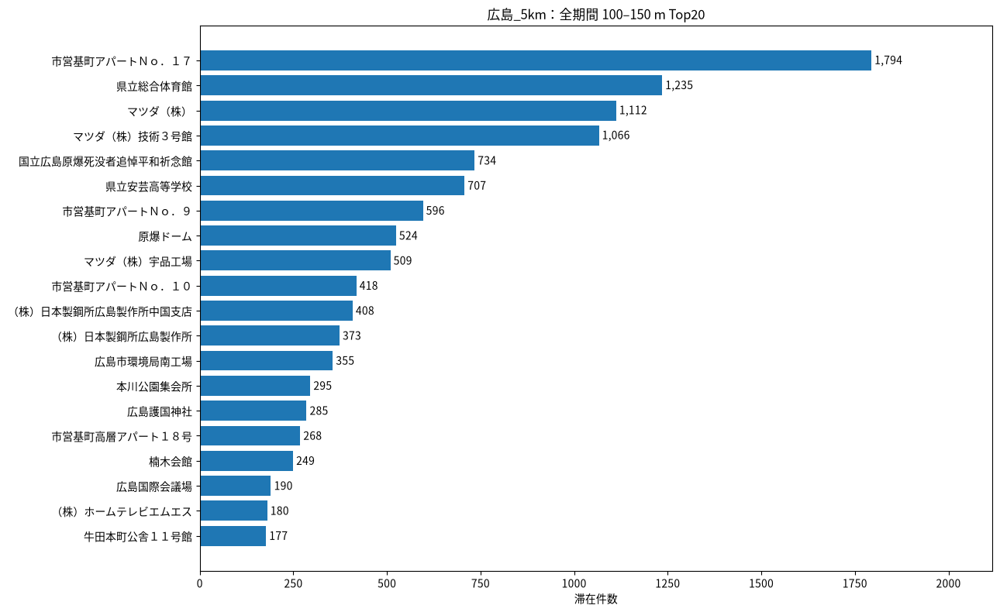


===== 広島_5km：150–200 m =====


,housename,滞在件数
0,市営基町アパートＮｏ．９,582
1,マツダ（株）,412
2,マツダ（株）技術３号館,412
3,市営基町アパートＮｏ．１７,388
4,県立総合体育館,347
5,市営基町アパートＮｏ．１０,258
6,日焼忠雄,218
7,マツダ（株）宇品工場,121
8,中央公園ファミリープール,111
9,広島市新千田ポンプ場,86


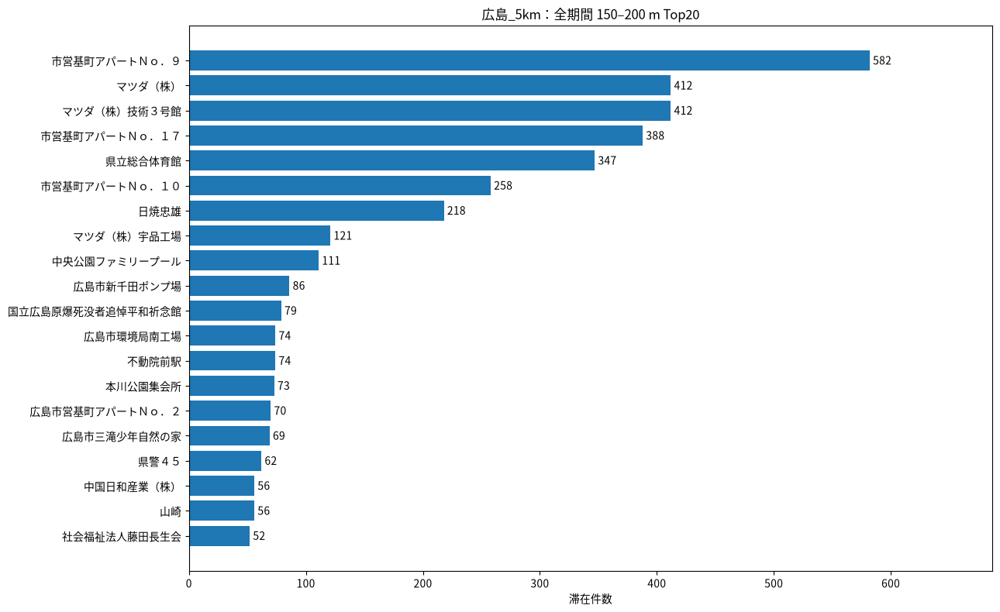


===== 広島_5km：200–300 m =====


,housename,滞在件数
0,広島市三滝少年自然の家,193
1,マツダ（株）宇品工場,112
2,宗教法人佛教正信会,52
3,水分神社,52
4,山崎,44
5,長友寿太郎,34
6,社会福祉法人藤田長生会,32
7,広島市新千田ポンプ場,32
8,山口祐之,30
9,和田文夫,28


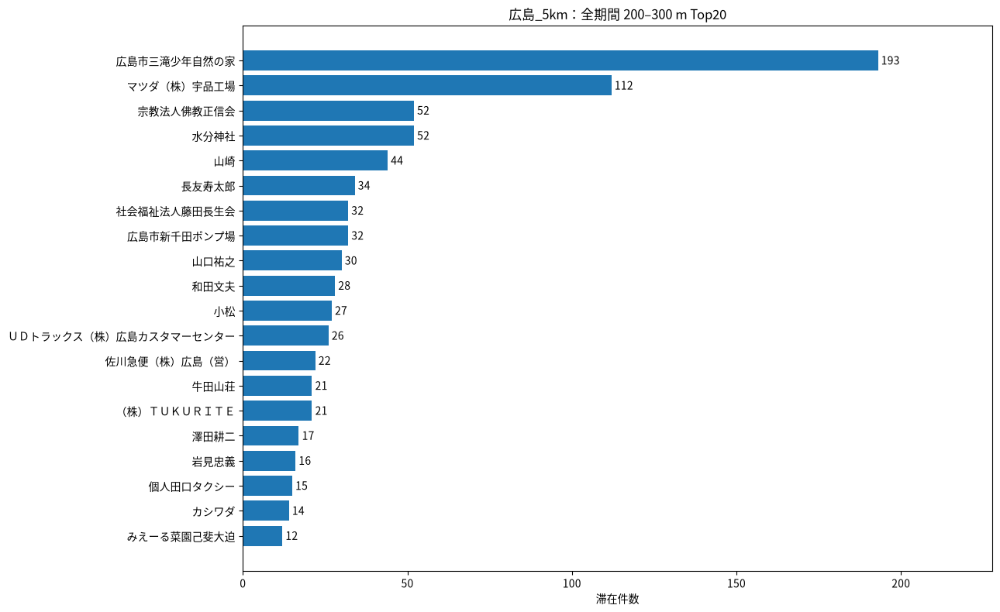


===== 広島_5km：300–400 m =====


,housename,滞在件数
0,宗教法人佛教正信会,26
1,マツダ（株）宇品工場,21
2,水分神社,16
3,（株）ＴＵＫＵＲＩＴＥ,16
4,マツダロジスティクス（株）,13
5,うぐいす共同作業所,13
6,（有）アスカ・ランテック,8
7,濱本徹,7
8,個人田口タクシー,7
9,山根二郎,7


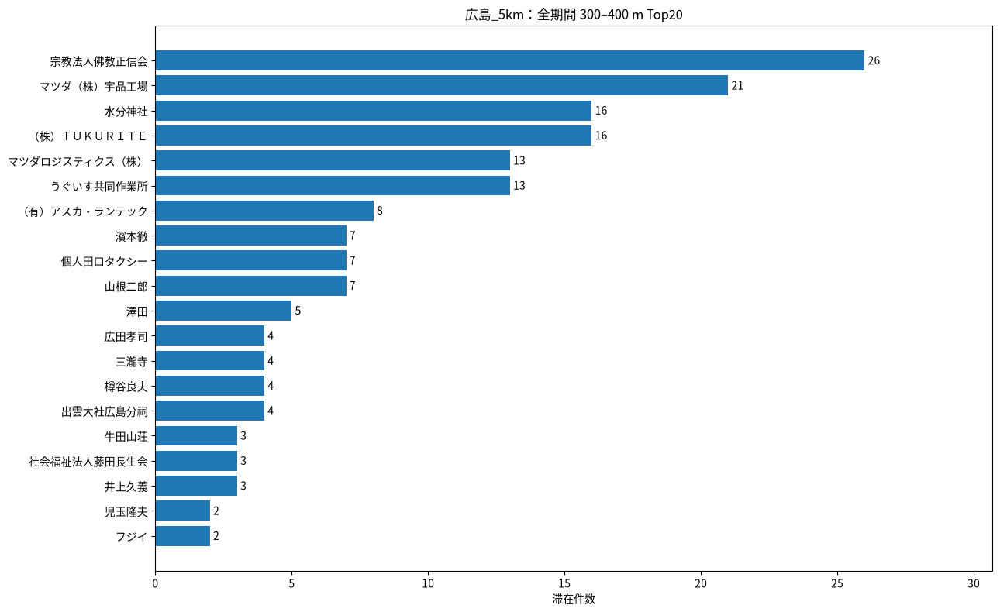


===== 広島_5km：400–500 m =====


,housename,滞在件数
0,マツダロジスティクス（株）,15
1,うぐいす共同作業所,8
2,広田孝司,8
3,水分神社,4
4,個人田口タクシー,1
5,井上久義,1
6,増原大東,1
7,広島銀行研修所,1


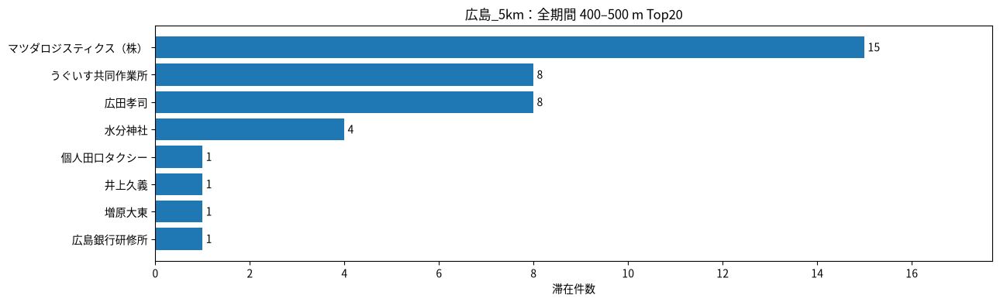

In [5]:
def get_top_buildings(stats, top_n):
    """全期間の距離帯別建物名TopNを取り出す。

    引数: statsは集計辞書、top_nは各距離帯の上位建物数。
    戻り値: {(地域名, 距離帯番号): [(housename, 件数), ...]}。
    処理条件: 同じhousenameをまとめ、行数で順位付けする。
    """
    tops = {}
    for label, st in stats.items():
        for band in range(len(DISTANCE_EDGES) - 1):
            counts = Counter({name: count for (b, name), count in st["top"].items() if b == band})
            tops[(label, band)] = counts.most_common(top_n)
    return tops


def plot_top_tables(tops):
    """全地域・距離帯のTopN表と横棒グラフを表示する。

    引数: topsはget_top_buildings()の結果。
    戻り値: なし。
    処理条件: カウントは全期間の全行を対象とする。
    """
    for (label, band), rows in tops.items():
        low, high = DISTANCE_EDGES[band:band + 2]
        print(f"\n===== {label}：{low}–{high} m =====")
        if not rows:
            print("該当する滞在なし")
            continue
        table = pd.DataFrame(rows, columns=["housename", "滞在件数"])
        display(table)
        fig, ax = plt.subplots(figsize=(13, max(4, len(table) * .4)))
        bars = ax.barh(range(len(table)), table["滞在件数"])
        ax.set_yticks(range(len(table)), labels=table["housename"])
        ax.invert_yaxis()
        ax.bar_label(bars, fmt="{:,.0f}", padding=3)
        ax.set(xlabel="滞在件数", title=f"{label}：全期間 {low}–{high} m Top{TOP_N}")
        ax.set_xlim(0, table["滞在件数"].max() * 1.18)
        plt.tight_layout()
        plt.show()


TOPS = get_top_buildings(STATS, TOP_N)
plot_top_tables(TOPS)

## 6. 地図のためのGPS中点の抽出（必要な場合のみ）

地図用サンプルを得るため、全ファイルをもう1回読みます。Top20の**選定は1周目の全件集計**に基づきます。各距離帯のGPS点は最大 `MAX_MAP_POINTS` 件に制限します（ファイル順・行順で先に出現した地点から取得）。この制限は集計件数を変えません。

In [6]:
def collect_map_points(files, region_data, tops, batch_size, max_points):
    """確定したTop建物に属するGPS中点だけを描画上限まで収集する。

    引数: filesは全入力、region_dataは地域情報、topsは全期間Top建物、
        batch_sizeは分割読込行数、max_pointsは地域・距離帯ごとの地点上限。
    戻り値: {(地域名, 距離帯番号): 地点DataFrame}。
    処理条件: 順序は入力ファイル順で、抽出数のみ制限する。
    """
    wanted = {key: set(name for name, _ in rows) for key, rows in tops.items()}
    samples = {key: [] for key in tops}
    npoints = Counter()
    for _, label, _, result in iter_region_results(files, region_data, batch_size):
        if all(npoints[(label, b)] >= max_points for b in range(len(DISTANCE_EDGES)-1)):
            continue
        nearest = result["building_match_type"].eq("nearest_polygon") & result["housename"].notna()
        part = result.loc[nearest, ["housename", "nearest_distance_m", "Midpoint_Longitude", "Midpoint_Latitude"]].copy()
        if part.empty:
            continue
        part["band"] = distance_bands(part["nearest_distance_m"])
        for band in range(len(DISTANCE_EDGES) - 1):
            key = (label, band)
            remaining = max_points - npoints[key]
            if remaining <= 0 or not wanted[key]:
                continue
            chosen = part.loc[part["band"].eq(band) & part["housename"].isin(wanted[key]),
                              ["housename", "Midpoint_Longitude", "Midpoint_Latitude"]].dropna().head(remaining)
            if not chosen.empty:
                samples[key].append(chosen)
                npoints[key] += len(chosen)
    return {key: pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=["housename", "Midpoint_Longitude", "Midpoint_Latitude"])
        for key, frames in samples.items()}


MAP_POINTS = collect_map_points(PARQUET_FILES, REGION_DATA, TOPS, BATCH_SIZE, MAX_MAP_POINTS) if MAKE_MAPS else {}

    ポリゴン内一致: 5 / 44801.parquet
    最近傍割当: 39
    建物割当成功: 44 / 44
    ポリゴン内一致: 89 / 290
    最近傍割当: 310
    建物割当成功: 438 / 438
    ポリゴン内一致: 7 / 32
    最近傍割当: 25
    建物割当成功: 32 / 32
    ポリゴン内一致: 63 / 231
    最近傍割当: 246
    建物割当成功: 342 / 342
    ポリゴン内一致: 5 / 29
    最近傍割当: 24
    建物割当成功: 29 / 29
    ポリゴン内一致: 64 / 256
    最近傍割当: 264
    建物割当成功: 355 / 355
    ポリゴン内一致: 11 / 36
    最近傍割当: 25
    建物割当成功: 36 / 36
    ポリゴン内一致: 57 / 219
    最近傍割当: 249
    建物割当成功: 340 / 340
    ポリゴン内一致: 6 / 35
    最近傍割当: 29
    建物割当成功: 35 / 35
    ポリゴン内一致: 75 / 291
    最近傍割当: 321
    建物割当成功: 440 / 440
    ポリゴン内一致: 8 / 42
    最近傍割当: 34
    建物割当成功: 42 / 42
    ポリゴン内一致: 77 / 282
    最近傍割当: 294
    建物割当成功: 402 / 402
    ポリゴン内一致: 8 / 36
    最近傍割当: 28
    建物割当成功: 36 / 36
    ポリゴン内一致: 103 / 342
    最近傍割当: 333
    建物割当成功: 488 / 488
    ポリゴン内一致: 6 / 42
    最近傍割当: 36
    建物割当成功: 42 / 42
    ポリゴン内一致: 124 / 373
    最近傍割当: 373
    建物割当成功: 545 / 545
    ポリゴン内一致: 4 / 14
    最近傍割当: 10
    建物割当成功: 14 / 14
    ポリゴン内一致: 95 / 298
    最近

## 7. 距離帯別Top20建物の地図（GPS地点は上限付き）

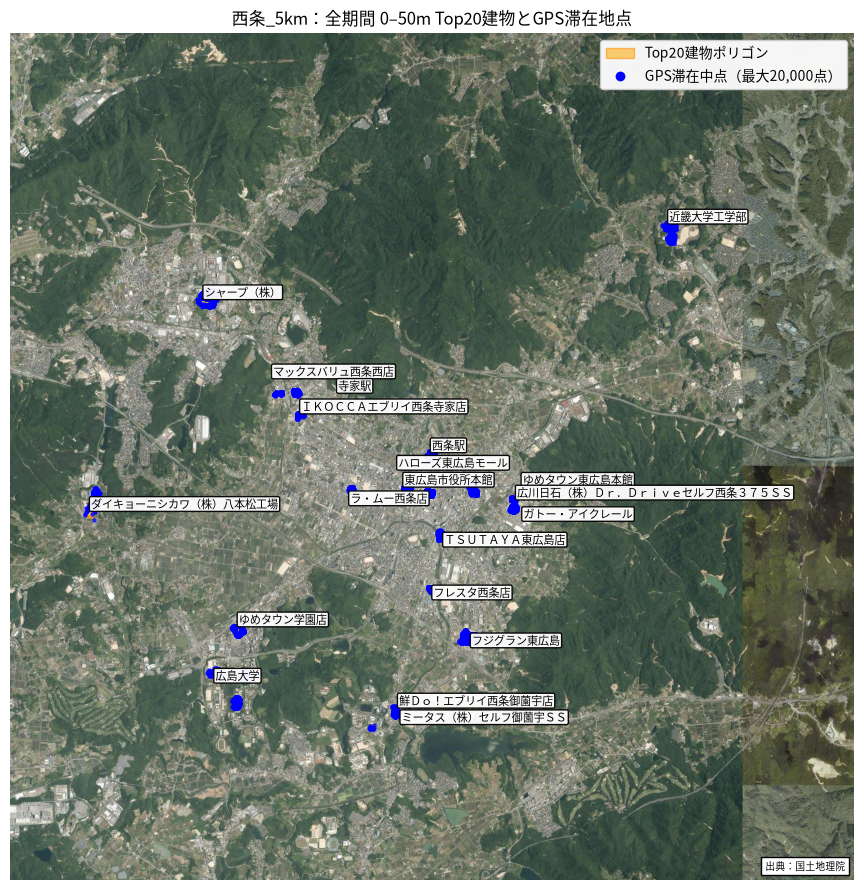

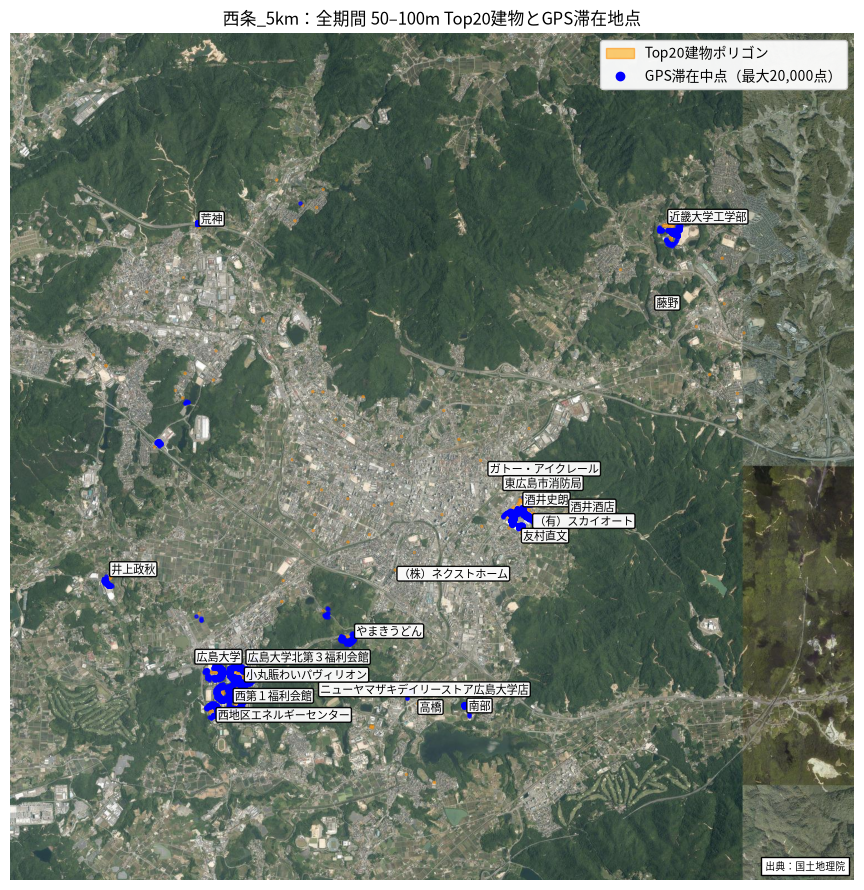

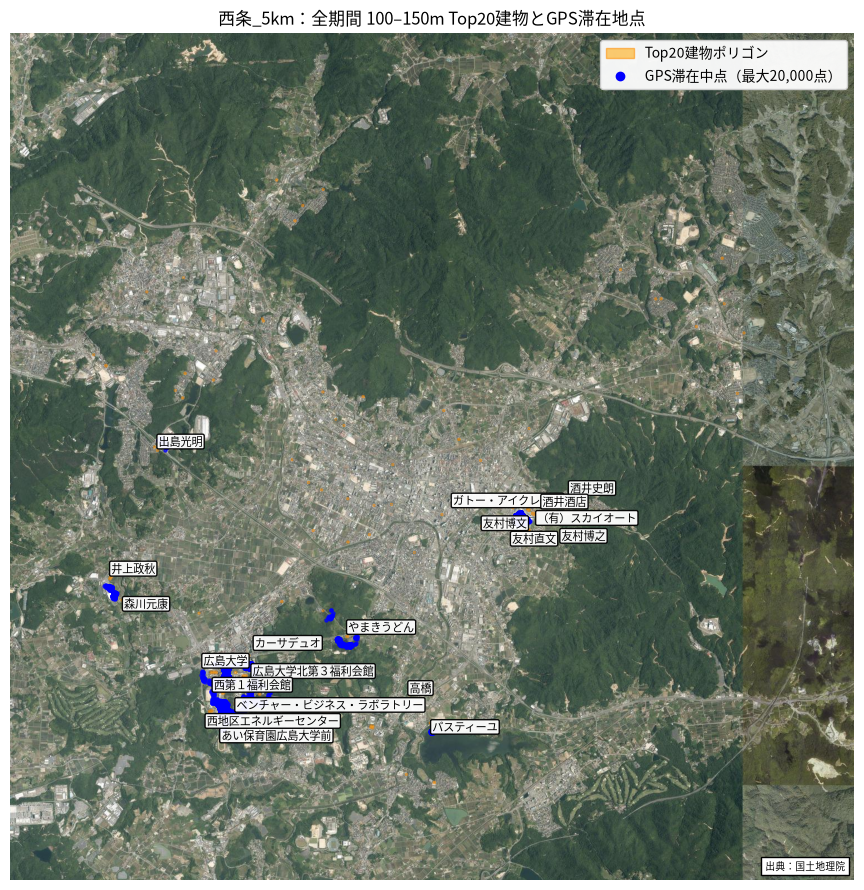

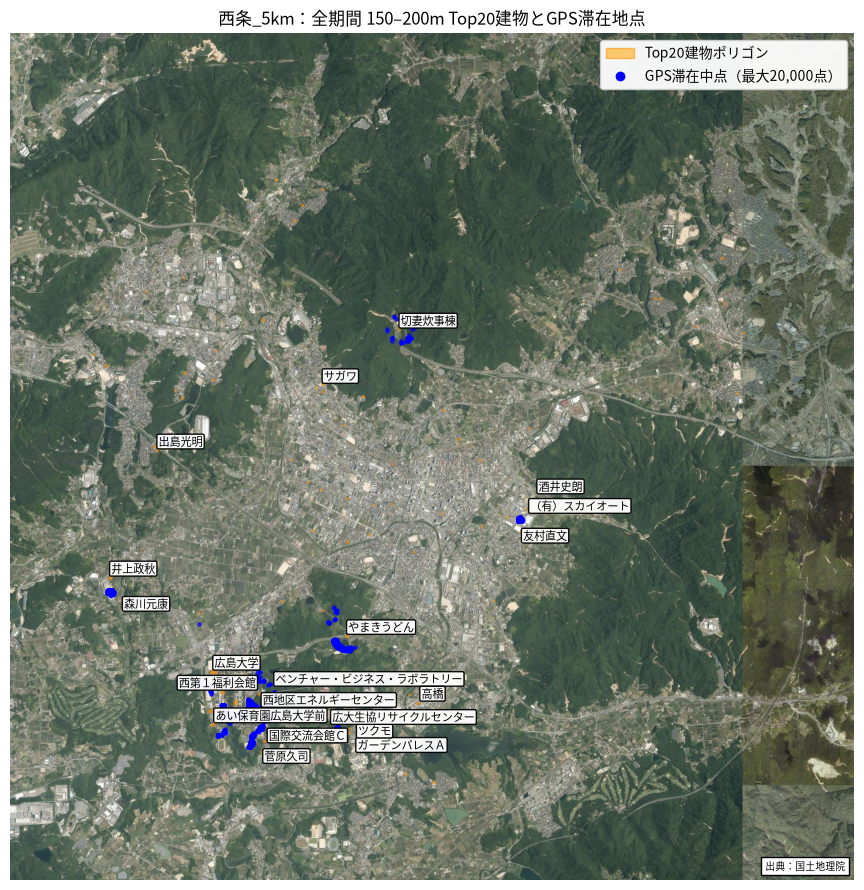

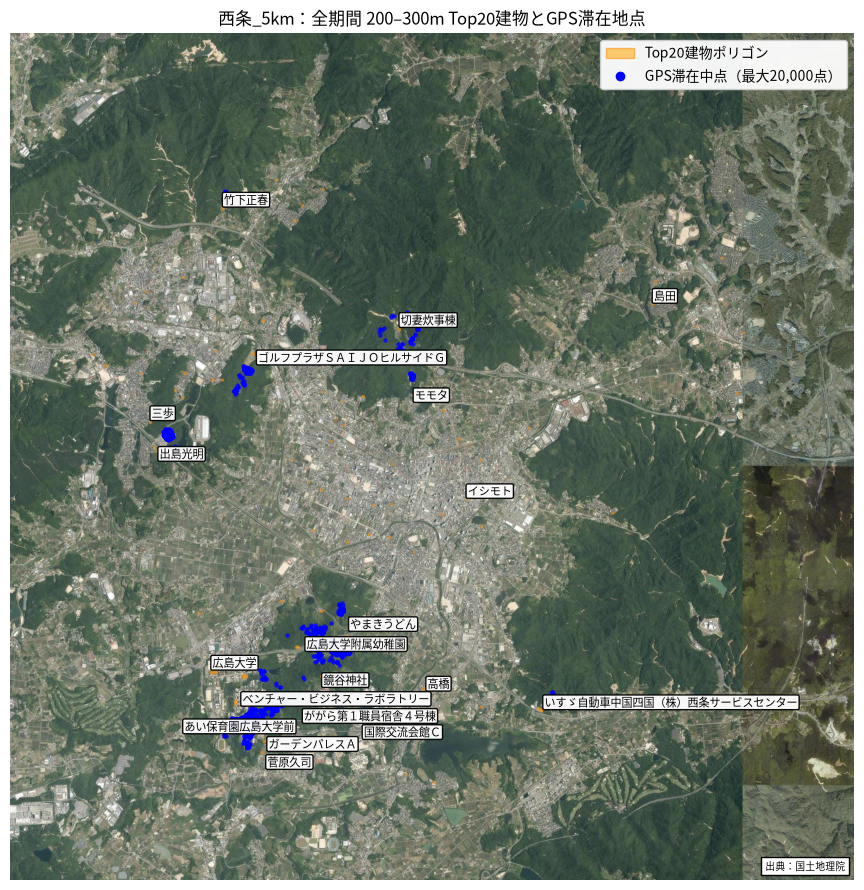

...

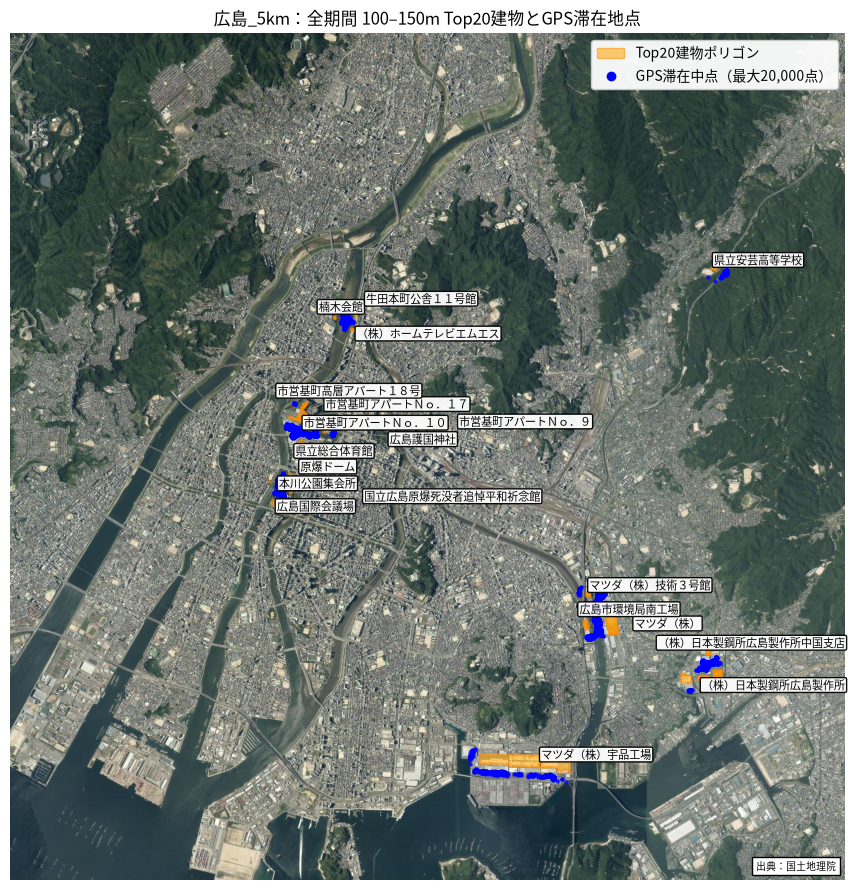

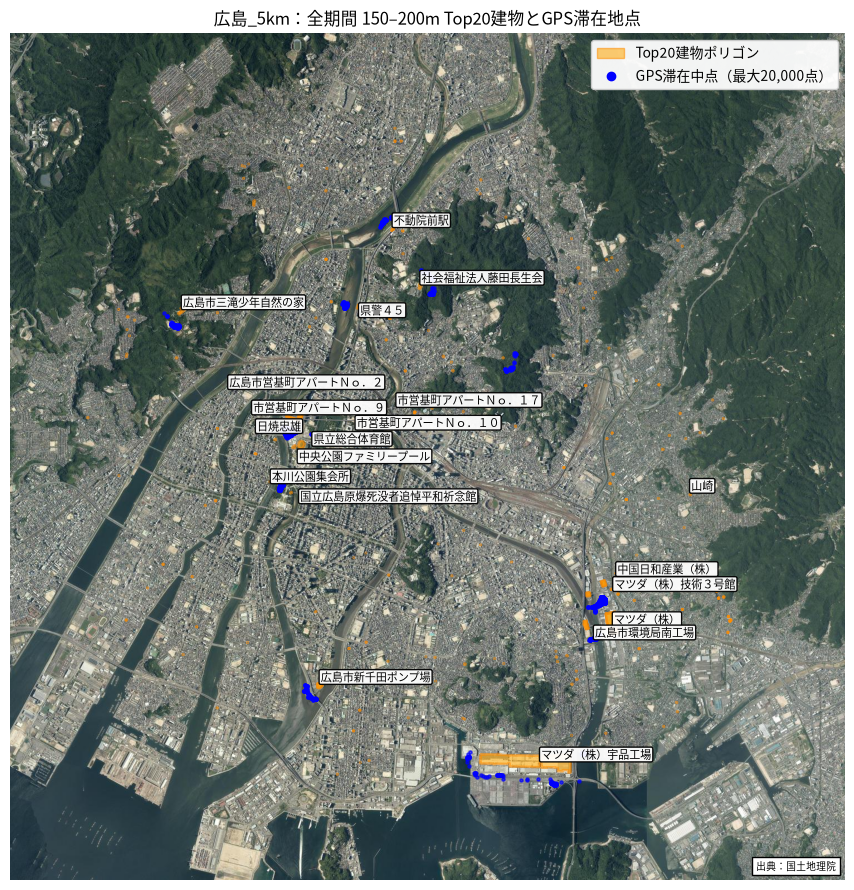

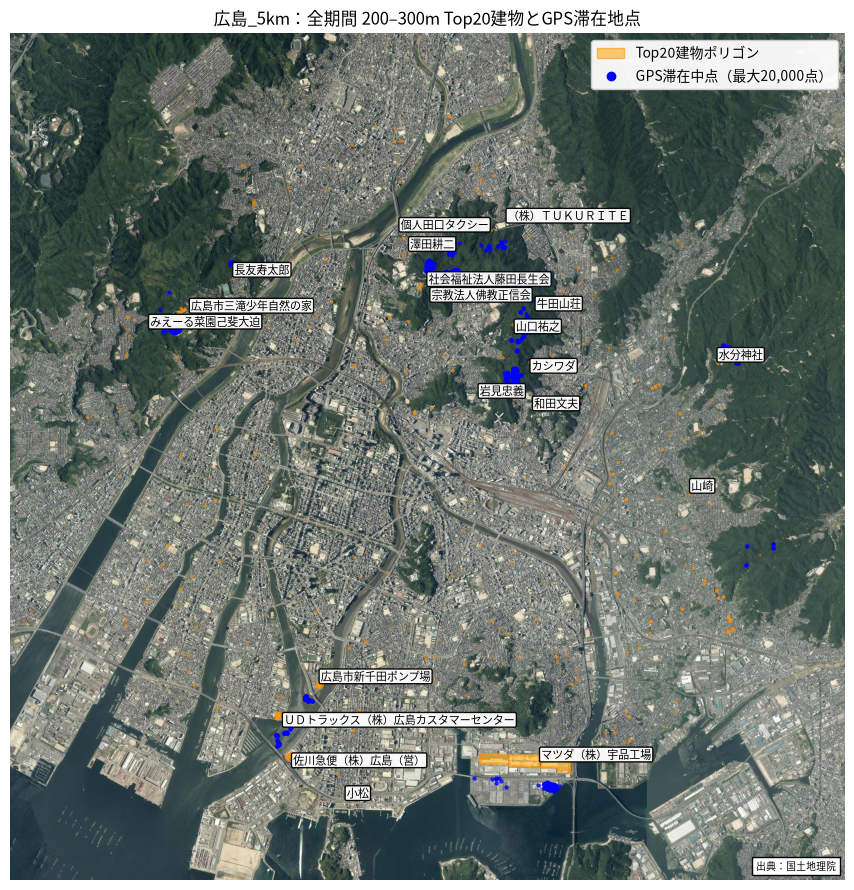

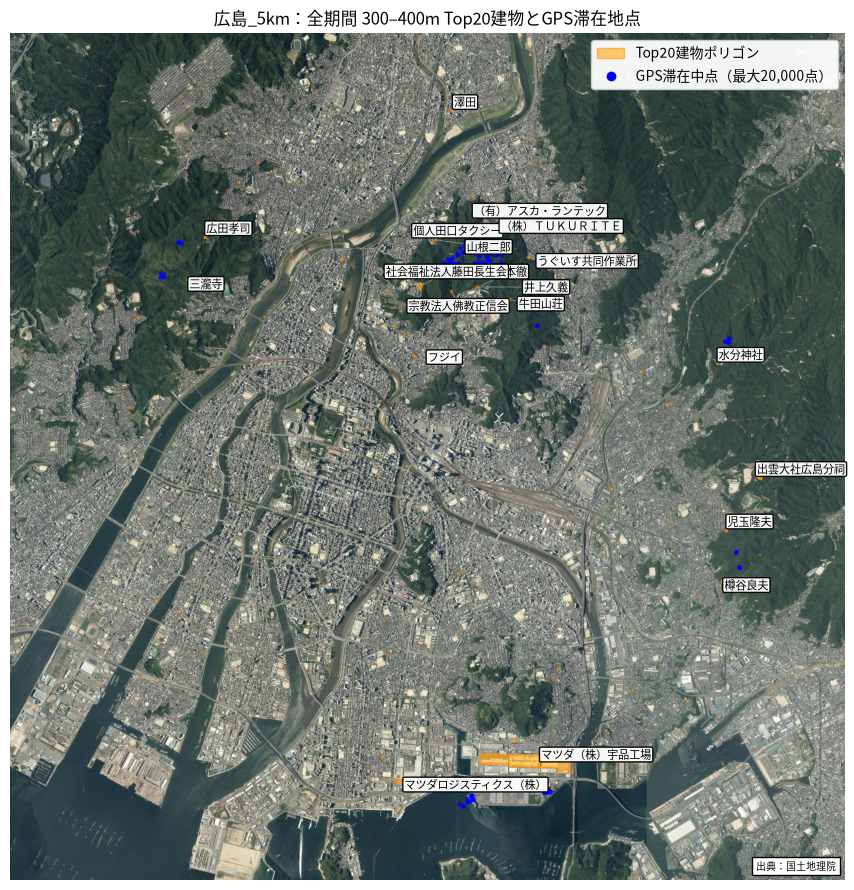

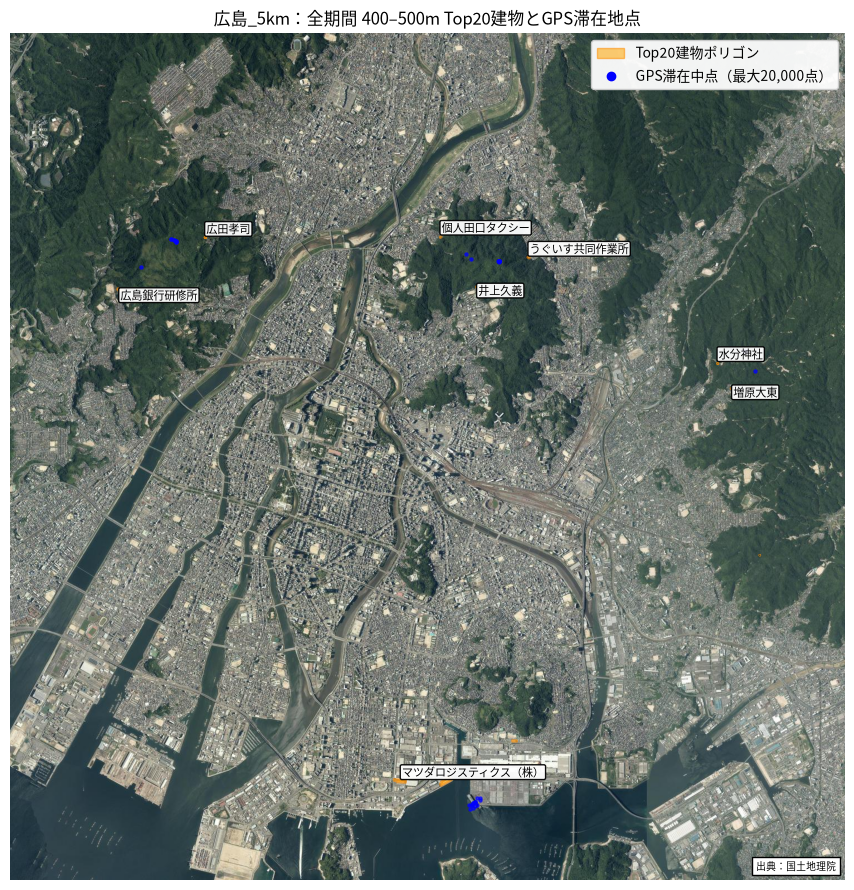

In [7]:
def add_aerial_basemap(ax):
    """国土地理院の航空写真を背景に表示する。

    引数: axはEPSG:3857のMatplotlib Axes。
    戻り値: なし。
    処理条件: 航空写真の取得失敗時は無背景で続行する。
    """
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    try:
        image, extent = ctx.bounds2img(
            xmin, ymin, xmax, ymax,
            source=GSI_URL, ll=False, zoom=GSI_ZOOM,
            use_cache=True, max_retries=0
        )
        ax.imshow(image, extent=extent, origin="upper", zorder=0)

        credit = AnchoredText(
            "出典：国土地理院",
            loc="lower right", prop={"size": 7}
        )
        credit.patch.set_facecolor("white")
        ax.add_artist(credit)

    except Exception as exc:
        print(f"航空写真取得失敗: {exc}")
        ax.set_facecolor("#f5f5f5")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)



def plot_top_maps(tops, map_points, region_data):
    """距離帯別Top建物ポリゴンとGPS滞在中点のサンプルを描画する。

    引数: topsは全期間順位、map_pointsは描画用中点、region_dataは建物情報。
    戻り値: なし（地図を表示）。
    処理条件: 建物名は既存のhousename、背景は地理院航空写真を使用する。
    """
    for (label, band), rows in tops.items():
        if not rows:
            continue
        buildings, _ = region_data[label]
        names = set(name for name, _ in rows)
        top = buildings.loc[buildings["housename"].isin(names)].to_crs(MAP_CRS)
        if top.empty:
            continue
        points_df = map_points[(label, band)]
        points = gpd.GeoDataFrame(points_df.copy(), geometry=gpd.points_from_xy(
            points_df["Midpoint_Longitude"], points_df["Midpoint_Latitude"]),
            crs=original.GPS_CRS).to_crs(MAP_CRS)
        label_map = top.dissolve(by="housename").reset_index()
        fig, ax = plt.subplots(figsize=(17, 11))
        # 全距離帯で同一地域の範囲に統一
        xmin, ymin, xmax, ymax = buildings.to_crs(MAP_CRS).total_bounds
        px, py = max((xmax-xmin)*.1, 600), max((ymax-ymin)*.1, 600)
        ax.set_xlim(xmin-px, xmax+px)
        ax.set_ylim(ymin-py, ymax+py)
        add_aerial_basemap(ax)
        top.plot(ax=ax, facecolor="orange", edgecolor="darkorange", alpha=.55, linewidth=1.8, zorder=4)
        if not points.empty:
            points.plot(ax=ax, color="blue", markersize=5, alpha=.65, zorder=5)
        rp = label_map.geometry.representative_point()
        x, y = rp.x.to_numpy(), rp.y.to_numpy()
        texts = [ax.text(xx, yy, str(name), fontsize=8,
                         bbox={"boxstyle":"round,pad=.15", "facecolor":"white", "alpha":.95}, zorder=6)
                 for xx, yy, name in zip(x, y, label_map["housename"])]
        if texts:
            adjust_text(texts, x=x, y=y, target_x=x, target_y=y,
                        ensure_inside_axes=True, expand_axes=False, iter_lim=300,
                        arrowprops={"arrowstyle":"-", "color":"gray", "lw":.7}, ax=ax)
        ax.legend(handles=[Patch(facecolor="orange", edgecolor="darkorange", alpha=.55,
                                 label="Top20建物ポリゴン"),
                           Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="blue",
                                  markeredgecolor="blue", label=f"GPS滞在中点（最大{MAX_MAP_POINTS:,}点）")],
                  loc="upper right", framealpha=.95)
        low, high = DISTANCE_EDGES[band:band+2]
        ax.set_title(f"{label}：全期間 {low}–{high}m Top{TOP_N}建物とGPS滞在地点")
        ax.set_axis_off()
        plt.show()


if MAKE_MAPS:
    plot_top_maps(TOPS, MAP_POINTS, REGION_DATA)

## 8. 少量のテスト（既存の建物割当条件は変更しない）

In [8]:
def test_assign_building() -> None:
    """既存の建物割当関数を3地点の人工データで検証する。

    引数: なし。
    戻り値: なし（成功時にメッセージ表示）。
    処理条件: 元コードの最近傍最大距離が500mである前提で検証する。
    """
    from shapely.geometry import Polygon
    shape = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
    test_buildings = gpd.GeoDataFrame({
        "housename": ["test"], "n_names": pd.Series([1], dtype="Int64"),
        "building_overlap": [False], "Building_Latitude": [0.0],
        "Building_Longitude": [0.0], "geometry": [shape]
    }, crs=original.METRIC_CRS)
    xy = gpd.GeoSeries(gpd.points_from_xy([5, 20, 700], [5, 5, 5]), crs=original.METRIC_CRS).to_crs(original.GPS_CRS)
    stays = pd.DataFrame({
        "Latitude_start": xy.y, "Latitude_end": xy.y,
        "Longitude_start": xy.x, "Longitude_end": xy.x,
    })
    test_result = original.assign_building(stays, test_buildings)
    assert test_result["building_match_type"].tolist() == [
        "polygon_intersection", "nearest_polygon", "nearest_polygon"]
    assert abs(test_result.loc[1, "nearest_distance_m"] - 10) < 0.01
    assert pd.isna(test_result.loc[2, "housename"])
    print("3地点のテスト成功")

test_assign_building()


    ポリゴン内一致: 1 / 3
    最近傍割当: 2
    建物割当成功: 2 / 3
3地点のテスト成功


## 解釈上の注意

- 件数は全期間の**滞在行数**であり、ユニークユーザー数ではありません。
- `unmatched` はポリゴン内不一致を示し、後に最近傍建物へ割り当てられた滞在も含みます。
- 既存の最近傍探索上限500m（実際の値は `original.MAX_NEAREST_DISTANCE_M`）を変更していません。上限外の滞在は距離分布に入りません。
- 複数候補との空間結合により入力滞在と結果行数が異なる可能性があります。
- 建物名が同じ複数ポリゴンは、元Notebookと同様に名前単位でまとめます。
- 地図用GPS点のサンプルは時系列順の先頭データであり、全期間の空間的な代表標本ではありません。
- 対象期間は `original.INPUT_DIR` 内の `trips_*.parquet` 全ファイルです。